In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency, ttest_ind, f_oneway
from statsmodels.stats.weightstats import ztest
from scipy.stats import f_oneway
import os

# Load dataframe

In [8]:
DF = pd.read_csv("/content/Derivable Judgement.csv")

# **PART B**

# ****1. Formulate at least two hypotheses from the dataset.****

In [13]:
Alpha = 0.05

# HYPOTHESIS 1 :
# H₀: Smoking has no effect on Diabetes prevalence.
# H₁: Smoking affects Diabetes prevalence.

CROSSTAB_TABLE = pd.crosstab(DF["smoking_status"] , DF["diabetes"])
Chi_2 , P1 , DOF , Expected = chi2_contingency(CROSSTAB_TABLE)

print("HYPOTHESIS 1 : Smoking vs Diabetes")
print("-" * 50)
print("Chi - square :" , round(Chi_2 , 3))
print("P - value :" , round(P1 , 4))


if P1 < Alpha :
    print("Reject H0 : Significant Dependent Found.")
else :
    print("Fail to Reject H0 : No significant Dependent Found.")


HYPOTHESIS 1 : Smoking vs Diabetes
--------------------------------------------------
Chi - square : 12.001
P - value : 0.0025
Reject H0 : Significant Dependent Found.


In [15]:
# HYPOTHESIS 2 :
# H0 : Mean glucose levels are equal for people with and without diabetes.
# H1 : Mean glucose levels are different.

Group_A = DF[DF["diabetes"] == True]["glucose_level"].dropna()
Group_B= DF[DF["diabetes"] == False]["glucose_level"].dropna()

T_TEST , P2 = ttest_ind(Group_A , Group_B , equal_var = False)

print("\n\nHYPOTHESIS 2 : Glucose vs Diabetes")
print("-" * 50)
print("Mean Glucose (diabetes):", round(Group_A.mean(), 2))
print("Mean Glucose (no diabetes):", round(Group_B.mean(), 2))
print("T - statistic:", round(T_TEST, 3))
print("P - value:", round(P2, 4))


if P2 < Alpha:
    print("Reject H0 : Mean Glucose Levels Differ Significantly.")
else:
    print("Fail to Reject H0 : No Significant Difference Found.")



HYPOTHESIS 2 : Glucose vs Diabetes
--------------------------------------------------
Mean Glucose (diabetes): 122.03
Mean Glucose (no diabetes): 95.24
T - statistic: 17.739
P - value: 0.0
Reject H0 : Mean Glucose Levels Differ Significantly.


# ****2. Calculate Confidence Intervals for key numerical data like age, weight, etc.****

In [17]:
# 95% Confidence Interval for Age
Age = DF["age"].dropna()

Mean_Age = Age.mean()
Error_Age = stats.sem(Age)
Lower_Age , Upper_Age = stats.t.interval(0.95 , len(Age) -1 , loc = Mean_Age , scale = Error_Age)

# ----------------------------------------------------------------------------------------------------------------------

# 95% Confidence Interval for Weight
Weight = DF["weight"].dropna()

Mean_Weight = Weight.mean()
Error_Weight = stats.sem(Weight)
Lower_Weight , Upper_Weight = stats.t.interval(0.95 , len(Weight) -1 , loc = Mean_Weight , scale = Error_Weight)

# ----------------------------------------------------------------------------------------------------------------------

# 95% Confidence Interval for BMI
BMI = DF["bmi"].dropna()

Mean_BMI = BMI.mean()
Error_BMI = stats.sem(BMI)
Lower_BMI , Upper_BMI = stats.t.interval(0.95 , len(BMI) -1 , loc = Mean_BMI , scale = Error_BMI)

# ----------------------------------------------------------------------------------------------------------------------

# 95% Confidence Interval for Blood Pressure
Blood_Pressure = DF["blood_pressure"].dropna()

Mean_Blood = Blood_Pressure.mean()
Error_Blood = stats.sem(Blood_Pressure)
Lower_Blood , Upper_Blood = stats.t.interval(0.95 , len(Blood_Pressure) -1 , loc = Mean_Blood , scale = Error_Blood)

# ----------------------------------------------------------------------------------------------------------------------

# 95% Confidence Interval for Cholesterol Level
Cholesterol_Level = DF["cholesterol_level"].dropna()

Mean_Cholesterol = Cholesterol_Level.mean()
Error_Cholesterol = stats.sem(Cholesterol_Level)
Lower_Cholesterol , Upper_Cholesterol = stats.t.interval(0.95 , len(Cholesterol_Level) -1 , loc = Mean_Cholesterol , scale = Error_Cholesterol)

# ----------------------------------------------------------------------------------------------------------------------

# 95% Confidence Interval for Glucose level
Glucose_level = DF["glucose_level"].dropna()

Mean_Glucose = Glucose_level.mean()
Error_Glucose = stats.sem(Glucose_level)
Lower_Glucose , Upper_Glucose = stats.t.interval(0.95 , len(Glucose_level) -1 , loc = Mean_Glucose , scale = Error_Glucose)

# ----------------------------------------------------------------------------------------------------------------------
# ----------------------------------------------------------------------------------------------------------------------
# ----------------------------------------------------------------------------------------------------------------------


# Age
print("Age")
print("-" * 50)
print("Mean Age :" , round(Mean_Age , 2))
print("Confidence Interval :" , round(Lower_Age , 2) , "to" , round(Upper_Age , 2))


# Weight
print("\nWeight")
print("-" * 50)
print("Mean Weight :" , round(Mean_Weight , 2))
print("Confidence Interval :" , round(Lower_Weight , 2) , "to" , round(Upper_Weight , 2))


# BMI
print("\nBMI")
print("-" * 50)
print("Mean BMI :" , round(Mean_BMI , 2))
print("Confidence Interval :" , round(Lower_BMI , 2) , "to" , round(Upper_BMI , 2))


# Blood Pressure
print("\nBlood Pressure")
print("-" * 50)
print("Mean Blood Pressure :" , round(Mean_Blood , 2))
print("Confidence Interval :" , round(Lower_Blood , 2) , "to" , round(Upper_Blood , 2))


# Cholesterol Level
print("\nCholesterol Level")
print("-" * 50)
print("Mean Cholesterol Level :" , round(Mean_Cholesterol , 2))
print("Confidence Interval :" , round(Lower_Cholesterol , 2) , "to" , round(Upper_Cholesterol , 2))


# Glucose level
print("\nGlucose level")
print("-" * 50)
print("Mean Glucose level :" , round(Mean_Glucose , 2))
print("Confidence Interval :" , round(Lower_Glucose , 2) , "to" , round(Upper_Glucose , 2))


Age
--------------------------------------------------
Mean Age : 43.32
Confidence Interval : 40.58 to 46.06

Weight
--------------------------------------------------
Mean Weight : 76.73
Confidence Interval : 75.0 to 78.46

BMI
--------------------------------------------------
Mean BMI : 25.88
Confidence Interval : 25.25 to 26.5

Blood Pressure
--------------------------------------------------
Mean Blood Pressure : 129.51
Confidence Interval : 127.44 to 131.58

Cholesterol Level
--------------------------------------------------
Mean Cholesterol Level : 203.22
Confidence Interval : 198.38 to 208.06

Glucose level
--------------------------------------------------
Mean Glucose level : 105.74
Confidence Interval : 103.16 to 108.32


# ****3. Find the Critical Value and p-value to interpret the test results.****

In [18]:
# Critical Value and P - value for T - test
Group_A = DF[DF["diabetes"] == True]["glucose_level"].dropna()
Group_B = DF[DF["diabetes"] == False]["glucose_level"].dropna()

T_Stats, P_Value = stats.ttest_ind(Group_A , Group_B , equal_var = False)

# Calculate Critical Value
n1 = len(Group_A)
n2 = len(Group_B)
v1 = Group_A.var() / n1
v2 = Group_B.var() / n2
DF_t = (v1 + v2) ** 2 / (v1 ** 2/ (n1 - 1) + v2 ** 2/(n2 - 1))
Critical_Value = stats.t.ppf(0.975 , DF_t)

print("T-statistic:" , round(T_Stats , 3))
print("Critical Value:", round(Critical_Value , 3))
print("P-value:", P_Value)

if P_Value < 0.05 :
    print("\nReject H0 : Significant result")
else :
    print("Fail to Reject H0 : Not significant")

T-statistic: 17.739
Critical Value: 1.98
P-value: 1.7881900579346078e-35

Reject H0 : Significant result


# ****4. Perform z-test or t-test based on sample size (mean comparison across groups).****

In [19]:
# Critical Value and P - value for T - test
Group_1 = DF[DF["diabetes"] == True]["glucose_level"].dropna()
Group_2 = DF[DF["diabetes"] == False]["glucose_level"].dropna()

Z_Stats, P_Value = ztest(Group_1 , Group_2)

print("Mean Glucose (Diabetes):" , round(Group_1.mean() , 2))
print("Mean Glucose (No Diabetes):" , round(Group_2.mean() , 2))
print("Z-statistic:", round(Z_Stats , 3))
print("P-value:", P_Value)

if P_Value < 0.05 :
    print("\nReject H0 : Significant result")
else :
    print("Fail to Reject H0 : Not significant")

Mean Glucose (Diabetes): 122.03
Mean Glucose (No Diabetes): 95.24
Z-statistic: 17.766
P-value: 1.2887664303826272e-70

Reject H0 : Significant result


# ****5. Conduct a chi-square test on categorical data (e.g., Smoking habit vs Disease).****

In [20]:
# Create a Contingency Table
Crosstab_Table = pd.crosstab(DF["smoking_status"] , DF["diabetes"])

# Perform Chi-square test
Chi_2 , P_Value , DOF , Expected = chi2_contingency(Crosstab_Table)

print("Contingency Table :")
print(Crosstab_Table)
print("\nChi-square Statistic:" , round(Chi_2 , 3))
print("P-value:", round(P_Value , 4))
print("Degrees of Freedom:", DOF)

if P_Value < 0.05:
    print("\nReject H0: Smoking status and diabetes are significantly associated.")
else:
    print("Fail to reject H0: No significant association.")

Contingency Table :
diabetes        False  True 
smoking_status              
Former Smoker      16     14
Non-Smoker         59     22
Smoker             15     22

Chi-square Statistic: 12.001
P-value: 0.0025
Degrees of Freedom: 2

Reject H0: Smoking status and diabetes are significantly associated.


# ****6. Perform an ANOVA test to check if age groups significantly differ in disease rate.****

In [21]:
Groups = []

for i in DF["age_group"].unique():
    Data = DF[DF["age_group"] == i]["diabetes"].astype(int)
    Groups.append(Data)


A = DF[DF["age_group"] == "Young"]["diabetes"].astype(int)
B = DF[DF["age_group"] == "Middle"]["diabetes"].astype(int)
C = DF[DF["age_group"] == "Old"]["diabetes"].astype(int)

F , P_Value = f_oneway(*Groups)

print("F-statistic:" , round(F , 4))
print("P-value:" , P_Value)

if P_Value < 0.05 :
    print("Reject H0")
else:
    print("Fail to reject H0")

F-statistic: 49.9794
P-value: 2.956077310192872e-26
Reject H0


# ****7. Calculate Covariance and Correlation between continuous variables (e.g., Age vs. BMI).****

In [22]:
print("Covariance : " , DF["age"].cov(DF["bmi"]))
print("Correlation : " , DF["age"].corr(DF["bmi"]))

Covariance :  35.77806122448978
Correlation :  0.5477822174875151


# ****8.Clearly state the result and interpretation (Accept/Reject H₀) of each test performed.****

In [23]:
# Z-test
print("Z - Test")
print("-" * 50)
print("Z-test: Reject H0")
print("Glucose levels differ significantly between diabetes groups.")

# Chi-square test
print("\n\nChi-square Test")
print("-" * 50)
print("Chi-square test: Reject H0")
print("Smoking status and diabetes are significantly associated.")

# ANOVA test
print("\n\nANOVA Test")
print("-" * 50)
print("ANOVA test: Reject H0")
print("Diabetes rates differ significantly across age groups.")

# Covariance and Correlation
print("\n\nCovariance and Correlation")
print("-" * 50)
print("Covariance:", 35.7781)
print("Correlation:", 0.5478)
print("Interpretation: Age and BMI have a moderate positive relationship.")

Z - Test
--------------------------------------------------
Z-test: Reject H0
Glucose levels differ significantly between diabetes groups.


Chi-square Test
--------------------------------------------------
Chi-square test: Reject H0
Smoking status and diabetes are significantly associated.


ANOVA Test
--------------------------------------------------
ANOVA test: Reject H0
Diabetes rates differ significantly across age groups.


Covariance and Correlation
--------------------------------------------------
Covariance: 35.7781
Correlation: 0.5478
Interpretation: Age and BMI have a moderate positive relationship.


# ****1. Diabetes By Smoking.png****

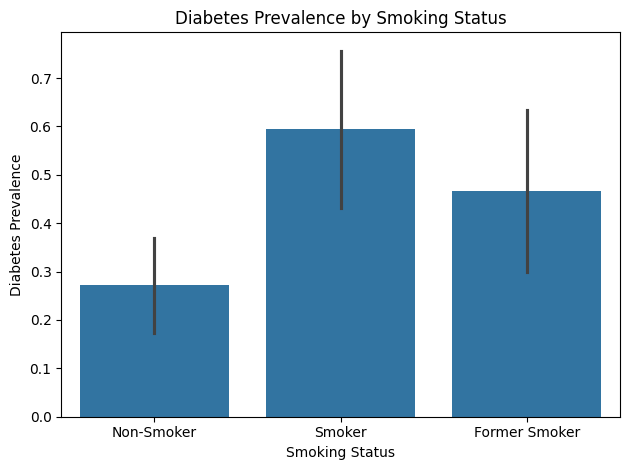

In [24]:
# Create output folder
os.makedirs("charts", exist_ok=True)

# 1. Diabetes by smoking status
sns.barplot(data = DF, x = "smoking_status" , y = "diabetes")
plt.title("Diabetes Prevalence by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Diabetes Prevalence")
plt.tight_layout()
plt.savefig("charts/fig1_diabetes_by_smoking.png", dpi=300)
plt.show()

# ****2. Contingency heatmap.png****

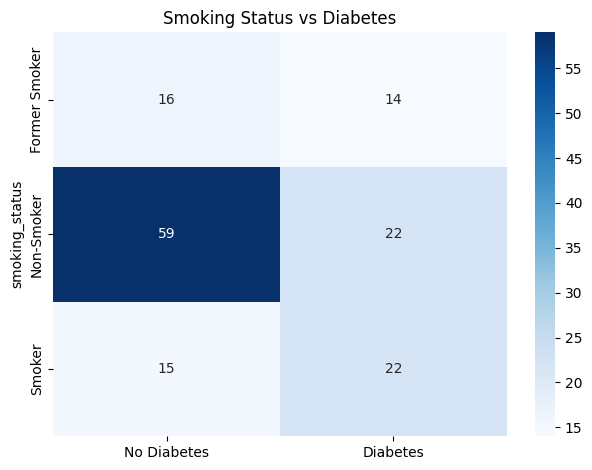

In [25]:
Crosstab_Table = pd.crosstab(DF["smoking_status"] , DF["diabetes"])
Crosstab_Table.columns = ["No Diabetes" , "Diabetes"]

sns.heatmap(Crosstab_Table , annot = True, fmt = "d" , cmap = "Blues")
plt.title("Smoking Status vs Diabetes")
plt.tight_layout()
plt.savefig("charts/fig2_contingency_heatmap.png", dpi=300)
plt.show()

# ****3. Glucose Distribution.png****

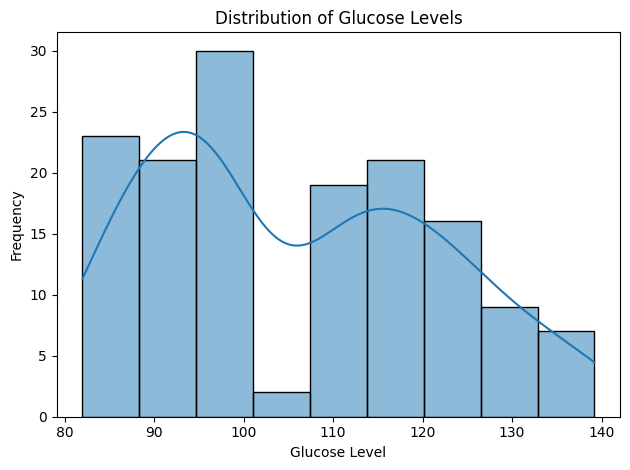

In [26]:
sns.histplot(data = DF , x = "glucose_level" , kde = True)

plt.title("Distribution of Glucose Levels")
plt.xlabel("Glucose Level")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig("charts/fig3_glucose_dist.png", dpi = 300)
plt.show()

# ****4. BP By Age.png****

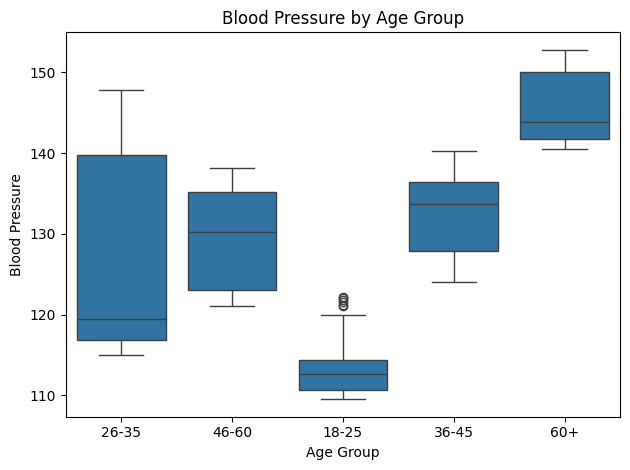

In [27]:
sns.boxplot(data = DF , x = "age_group" , y = "blood_pressure")

plt.title("Blood Pressure by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Blood Pressure")
plt.tight_layout()

plt.savefig("charts/fig4_bp_by_age.png", dpi = 300)
plt.show()

# ****5. BMI By BP Scatter.png****

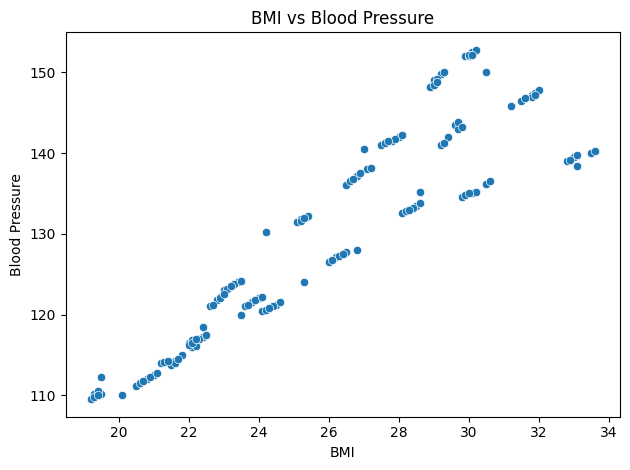

In [28]:
sns.scatterplot(data = DF , x = "bmi" , y = "blood_pressure")

plt.title("BMI vs Blood Pressure")
plt.xlabel("BMI")
plt.ylabel("Blood Pressure")
plt.tight_layout()

plt.savefig("charts/fig5_bmi_bp_scatter.png", dpi = 300)
plt.show()

# ****6 Corr Metrix.png****

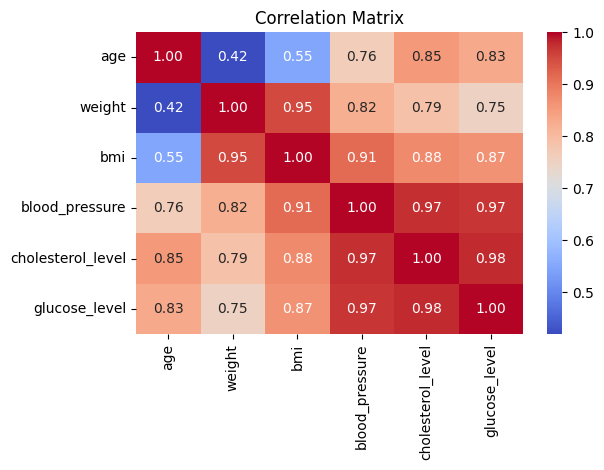

In [29]:
Corr = DF.select_dtypes(include = "number").corr()

sns.heatmap(Corr , annot = True , cmap = "coolwarm" , fmt = ".2f")

plt.title("Correlation Matrix")
plt.tight_layout()

plt.savefig("charts/fig6_corr_matrix.png", dpi=300)
plt.show()